# Intro to Neural Networks
- traditional ML system rely on humans for feature selection
- representation ML-based system select features to attend to
- deep-learning algos:
    - learn what features mattter
    - scalable
- neural networks: most common class of deep learning algos
    - neurons: 
        - building blocks of learning
        - math function applied to the inputs (vector of x variables/features)
        - produces scalar output y
        - single neuron can be connected to multiple neurons in the next layer
    - model parameters:
        - each connection is associated w/ a weight
        - how sensitive the neuron is to the output of the first neuron
        - 'neurons that fire together are wired together'
    - Feed Forward Network (FFNs): 
        - each layer identifies a set of patterns
        - early layers extract more granular patterns (e.g., pixels)
        - deeper layers identify more abstract patterns (e.g., edges/corners -> id objects)
        - input/output layers: visible layers
        - hidden layers: middle layers
        - each layer passes data to the next
        - each layer consists of interconnected neurons
    - Functions:
        - affine transformation: linear function in the form of wx + b = y
        - activation: help discover non-linear relationships
            - identity function: takes the same output of the affine function -> linear neuron
            - ReLU: max(input, 0)
            - logit: s-curve function
            - tanh
            - step function
            - SoftMax: 
                - logit curve
                - output: [0,1]
                - can be interpreted as a probability
        - active region: regions where y is senstive to change in inputs
            - slope = gradient
            - saturated: not sensitive to change in input
            - need to learn from the active region

# PyTorch
- deep learning framework
- deeply tied to Python
    - create NN in python
    - use existing Python libraries and debuggers
- neural network can be redefined dynamically
    - dynamic computation graph
- write code, run immediately
    - no separate build and run
    - debugging w/ PyCharm, pdb
    - visualization w/ matplotlib, seaborn
    - need to set up REST API e.g., Flask
    - use torch.nn.DataParallel to use GPUs (easier)


In [2]:
import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print("GPU mode active")
else:
    print("CPU mode active - ready for learning!")

PyTorch version: 2.12.0+cpu
CUDA available: False
CPU mode active - ready for learning!


# Tensor Initiation
- central unit of data in PyTorch
    - similar to Numpy, but can be instantiated on GPUs for parallel processing
- set of primitive values shaped into an array of any n-dimensions
    - scalars are 0D tensors
    - vectors are 1D
    - matrices are 2D
    - N-D tensors
- initiation:
    - torch.tensor(shape)
    - .rand: [0,1]
    - .randn: normal distribution w/ mean=0 and std = 1
    - .randint(min, max, (,))
    - torch.full((,), fill_value=)
    - torch.ones()
    - torch.zeros_like(tensor) -> adopts the shape of another tensor
    - torch.eye() -> square matrix w/ 1 along the main diagonal
    - torch.nonzero(tensor) -> returns the index locations of non-zero values
    - torch.linspace(start, end, step)
- datatype:
    - initialize: 
        - dtype=torch.int32
        - torch.ShortTensor() for dtype=torch.int16
    - change: 
        - .type(torch.int32)
        - .type(torch.half)
- tensor types:
    - sparse: torch.sparse_coo_tensor(indices of non-zero v, values, size, dtype=, etc.)

In [3]:
torch.get_default_dtype()

torch.float32

In [4]:
tensor_arr = torch.tensor([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
print(tensor_arr)

tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])


In [7]:
print(torch.is_tensor(tensor_arr))
print(torch.numel(tensor_arr))

True
9


In [7]:
tensor_uninitialized = torch.randn(3, 3)
print(tensor_uninitialized)

tensor([[ 0.8432, -0.2627, -0.0954],
        [ 0.0238,  0.5630, -0.6210],
        [ 0.0041, -0.7245, -1.2307]])


In [9]:
tensor_int = torch.tensor([1, 2, 3]).type(torch.int32)
tensor_float = torch.tensor([1.0, 2.0, 3.0]).type(torch.float32)
tensor_bool = torch.tensor([True, False, True], dtype=torch.bool)
print(tensor_int)
print(tensor_float)
print(tensor_bool)

tensor([1, 2, 3], dtype=torch.int32)
tensor([1., 2., 3.])
tensor([ True, False,  True])


In [12]:
int_tensor = torch.ShortTensor([1, 2, 3])
print(int_tensor)

tensor([1, 2, 3], dtype=torch.int16)


In [13]:
tensor_half = torch.tensor([1.0, 2.0, 3.0], dtype=torch.half)
print(tensor_half)

tensor([1., 2., 3.], dtype=torch.float16)


In [14]:
tensor_filled = torch.full((3, 3), fill_value=7)
print(tensor_filled)

tensor([[7, 7, 7],
        [7, 7, 7],
        [7, 7, 7]])


In [16]:
tensor_ones = torch.ones((2, 3))
tensor_zeros = torch.zeros_like(tensor_ones, dtype=torch.int32)
print(tensor_ones)
print(tensor_zeros)

tensor([[1., 1., 1.],
        [1., 1., 1.]])
tensor([[0, 0, 0],
        [0, 0, 0]], dtype=torch.int32)


In [18]:
tensor_eye = torch.eye(4, dtype=torch.int32)
print(tensor_eye)

tensor([[1, 0, 0, 0],
        [0, 1, 0, 0],
        [0, 0, 1, 0],
        [0, 0, 0, 1]], dtype=torch.int32)


In [20]:
sparse = torch.nonzero(tensor_eye)
print(sparse)

tensor([[0, 0],
        [1, 1],
        [2, 2],
        [3, 3]])


In [26]:
sparse_tensor = torch.sparse_coo_tensor(tensor_eye.nonzero().t(), torch.ones(tensor_eye.nonzero().shape[0]), tensor_eye.shape)
print(sparse_tensor)
dense = sparse_tensor.to_dense()
print(dense)

tensor(indices=tensor([[0, 1, 2, 3],
                       [0, 1, 2, 3]]),
       values=tensor([1., 1., 1., 1.]),
       size=(4, 4), nnz=4, layout=torch.sparse_coo)
tensor([[1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0., 0., 0., 1.]])


# Tensor Operation
- in-place operations: have an '_' suffix
    - .fill_()
    - .add_()
    - .sqrt_()
- out of place operation: store result in new tensor
    - .add() -> add value to all element in tensor
    - .cat() -> concatenate
- .size() returns the size of the tensor
- .view() returns the tensor in a different shape; 
    - must be compatible w/ original shape
    - share the same underlying memory
- reshaping:
    - .unsqueeze() -> adds extra dimension
    - .squeeze()
    - .transpose()

In [28]:
init_tensor = torch.rand(3, 3)
print(init_tensor)

tensor([[0.0183, 0.7418, 0.3417],
        [0.9569, 0.8892, 0.2278],
        [0.6637, 0.2603, 0.6373]])


In [29]:
init_tensor.fill_(10)
print(init_tensor)

tensor([[10., 10., 10.],
        [10., 10., 10.],
        [10., 10., 10.]])


In [30]:
new_tensor = init_tensor.add(5)
print(new_tensor)

tensor([[15., 15., 15.],
        [15., 15., 15.],
        [15., 15., 15.]])


In [31]:
new_tensor.sqrt_()
print(new_tensor)

tensor([[3.8730, 3.8730, 3.8730],
        [3.8730, 3.8730, 3.8730],
        [3.8730, 3.8730, 3.8730]])


In [33]:
x = torch.linspace(0, 10, steps=8)
print(x)

tensor([ 0.0000,  1.4286,  2.8571,  4.2857,  5.7143,  7.1429,  8.5714, 10.0000])


In [34]:
chunked = torch.chunk(x, 4, 0)
print(chunked)

(tensor([0.0000, 1.4286]), tensor([2.8571, 4.2857]), tensor([5.7143, 7.1429]), tensor([ 8.5714, 10.0000]))


In [35]:
t1 = chunked[0]
t2 = chunked[1]
t_concatenated = torch.cat((t1, t2), dim=0)
print(t_concatenated)

tensor([0.0000, 1.4286, 2.8571, 4.2857])


In [36]:
# slicing operation
new_tensor[1:, 1:]

tensor([[3.8730, 3.8730],
        [3.8730, 3.8730]])

In [39]:
new_tensor.view(9, 1)

tensor([[3.8730],
        [3.8730],
        [3.8730],
        [3.8730],
        [3.8730],
        [3.8730],
        [3.8730],
        [3.8730],
        [3.8730]])

In [45]:
unsq = torch.unsqueeze(new_tensor, dim=0)
unsq, unsq.shape

(tensor([[[3.8730, 3.8730, 3.8730],
          [3.8730, 3.8730, 3.8730],
          [3.8730, 3.8730, 3.8730]]]),
 torch.Size([1, 3, 3]))

In [47]:
init_tensor = torch.rand(2, 3)
transposed = init_tensor.transpose(0, 1)
print(init_tensor)
print(transposed)

tensor([[0.2889, 0.7130, 0.7754],
        [0.1915, 0.5466, 0.1773]])
tensor([[0.2889, 0.1915],
        [0.7130, 0.5466],
        [0.7754, 0.1773]])


# Element-wise / matrix ops
- torch.sort(tensor)
    - default sort by the last dimension
    - sort values by dim
    - indices = indices from the original tensor in the sorted order
- torch.abs(tensor)
    - convert to abs values
- torch.clamp(tensor, min=, max=)
    - imposes upper and lower bound range for values
- arithmetic ops:
    - tensor.add(t2)
    - tensor.div(t2)
    - tensor.mul(t2)
- matrix ops:
    - torch.dot(t1, t2) -> dot product
    - matrix.mv(vector) -> multiply matrix by vector assuming compatible shapes
    - matrix1.mm(matrix2) -> matrix multiplication
    - .argmax / argmin -> position of max/min value

In [1]:
import torch
tensor_rand = torch.randint(0, 100, (3, 3))
tensor_rand

tensor([[61, 41, 72],
        [49, 56, 57],
        [13, 36,  9]])

In [2]:
sorted_tensor, indices = torch.sort(tensor_rand)
print("Sorted Tensor:")
print(sorted_tensor)

Sorted Tensor:
tensor([[41, 61, 72],
        [49, 56, 57],
        [ 9, 13, 36]])


In [3]:
indices

tensor([[1, 0, 2],
        [0, 1, 2],
        [2, 0, 1]])

In [55]:
tensor_float = torch.FloatTensor([-1.0, -2.0, 3.0])
tensor_abs = torch.abs(tensor_float)
tensor_abs

tensor([1., 2., 3.])

In [59]:
abs_tensor = tensor_float.abs()
abs_tensor

tensor([1., 2., 3.])

In [57]:
a = tensor_rand.add(sorted_tensor)
a

tensor([[24, 73, 73],
        [ 8, 81, 81],
        [24, 23, 35]])

In [58]:
div = tensor_rand.div(sorted_tensor)
div

tensor([[1.0000, 1.2121, 0.8250],
        [1.0000, 4.7857, 0.2090],
        [3.0000, 0.3529, 0.9444]])

In [61]:
clamped = div.clamp(min=0.5, max=2.0)
clamped

tensor([[1.0000, 1.2121, 0.8250],
        [1.0000, 2.0000, 0.5000],
        [2.0000, 0.5000, 0.9444]])

In [64]:
dot = tensor_abs.dot(abs_tensor)
dot

tensor(14.)

In [73]:
mm = tensor_abs.unsqueeze(1).mm(abs_tensor.unsqueeze(1).t())
mm 

tensor([[1., 2., 3.],
        [2., 4., 6.],
        [3., 6., 9.]])

In [69]:
t1 = torch.tensor([1, 2, 3])
t2 = torch.tensor(([4, 5, 6], [5, 6, 7]))
mv = t2.mv(t1)
mv

tensor([32, 38])

In [75]:
mm.argmax(dim=1)

tensor([2, 2, 2])

# Converting between Tensors and Arrays
- PyTorch tensors are Numpy arrays w/ the ability to be executed on GPUs
- conversion:
    - array = tensor.numpy()
    - tensor = torch.as_tensor(array) -> avoid making copies
    - tensor = torch.tensor(array) -> creates a copy
- share the same memory

In [4]:
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
t1 = torch.rand(3, 3)
print(t1)
print(t1.type())

tensor([[0.6407, 0.8262, 0.1574],
        [0.7263, 0.6354, 0.0228],
        [0.0641, 0.1729, 0.3236]])
torch.FloatTensor


In [7]:
a1 = t1.numpy()
print(type(a1))
a1

<class 'numpy.ndarray'>


array([[0.64074826, 0.8261878 , 0.1574291 ],
       [0.7263417 , 0.63536584, 0.02278167],
       [0.06414431, 0.17287791, 0.32356793]], dtype=float32)

In [8]:
torch.is_tensor(t1), torch.is_tensor(a1)

(True, False)

In [9]:
a1[0,0] = 100
t1

tensor([[1.0000e+02, 8.2619e-01, 1.5743e-01],
        [7.2634e-01, 6.3537e-01, 2.2782e-02],
        [6.4144e-02, 1.7288e-01, 3.2357e-01]])

In [10]:
t1[0] = 1
a1

array([[1.        , 1.        , 1.        ],
       [0.7263417 , 0.63536584, 0.02278167],
       [0.06414431, 0.17287791, 0.32356793]], dtype=float32)

In [12]:
# array to tensors
a1 = np.array([[1, 2, 3], [4,5,6]])
t1 = torch.as_tensor(a1)
t1

tensor([[1, 2, 3],
        [4, 5, 6]])

In [13]:
a1[1,1]=10
t1

tensor([[ 1,  2,  3],
        [ 4, 10,  6]])

# GPU / CUDA support
- GPU are highly parallelized OOM faster than CPUs
- Pytorch is architected for GPUs
- CUDA: 
    - parallel computing platform and API
    - torch.cuda for CUDA operations
        - torch.cuda.FloatTensor for specific tensor types
        - torch.cuda.device to select GPUs
    - ops on tensors across devices will cause errors unless explicitly enabled peer-to-peer memory access
- asynchronous execution
    - enqueued to a particular device and executed later (FIFO)
    - allow more parallel executions
    - can force synchronous execution using envir. variable (CUDA_LAUNCH_BLOCKING =1)
- copying is required to move tensor from one device to another
    - t1=t0.to(device=cuda1)
    - t1=t0.cuda() to create a copy of t0 on the default cuda device
    - ops on tensors in diff devices will fail, e.g., CPU-to-cuda1, cuda1-to-cuda2


# Gradient Descent Optimization
- process to train neural networks
- objective: minimize loss (according to loss function) wrt weights and bias
    - for linear, smallest value of MSE (mean squared error)
- Process:
    - plot MSE wrt w and b (3D) to form a loss surface
    - initialize some value of w and b to generate a starting position on loss surface
    - use the GD algo to converge to the optimal parameters ('walk down the GD slop)
    - Forward pass: use the current model parameters to make a prediction
        - theta = y_pred - y_actual = error
            - MSE for regression models
            - cross-entropy for logistic models
    - error fed to optimizer to calc gradient
    - Backward pass (back propagation): adjusting model parameters based on gradient optimization
        - layer by layer, starting from the last
        - optimization occurs at each step of the backward pass
    - train iteratively until the parameters converge to optimal values
        - ie. gradients converge to 0
- Gradient:
    - vector of partial derivatives of loss function wrt parameters
        - measures the sensitivity of loss to marginal changes in a particular weight
    - apply to a specific time t
    - parameters(t+1) = parameters(t) - learning_rate * gradient(theta(t))
        - learning rate is the size of the step taken to reduce gradient at each step
            - small values -> longer training time
            - large values -> training might not converge
- Autograd: PyTorch library for calc gradients
    - uses auto differentiation technique
        - based on Taylor's series expansion
        - back propagation uses reverse auto differentiation
    - tensor.requires_grad 
        - default = False
        - .requires_grad_() set to True
        - if any input tensor is set to True, will propagate to output tensors
    - tensor.grad
        - gradient property
        - None until perform backward pass
    - tensor.grad_fn -> computation graph
        - references the last function
    - tensor.backward()
        - function call for backward pass on output tensor
        - generates gradient values that fill .grad property of input tensors

In [29]:
t1 = torch.randint(0,100,(2,3), dtype=torch.float16)
t2 = torch.randint(0,100,(2,3), dtype=torch.float16)
t1, t2

(tensor([[54.,  4.,  6.],
         [20., 67.,  7.]], dtype=torch.float16),
 tensor([[38., 99., 62.],
         [85., 69.,  7.]], dtype=torch.float16))

In [30]:
t1.requires_grad

False

In [31]:
t1.requires_grad_()
t1.requires_grad, t1

(True,
 tensor([[54.,  4.,  6.],
         [20., 67.,  7.]], dtype=torch.float16, requires_grad=True))

In [32]:
print(t1.grad)

None


In [33]:
output_t = (t1 * t2).mean()
output_t.grad_fn

In [34]:
output_t.backward()
print(t1.grad)

tensor([[ 6.3320, 16.5000, 10.3281],
        [14.1641, 11.5000,  1.1660]], dtype=torch.float16)


In [36]:
t_new = t1 * 3
t_new.grad_fn

In [40]:
def calculate(t):
    return t * 3

@torch.no_grad()
def calculate_nograd(t):
    return t*3

In [42]:
result_t = calculate(t1)
result_t, result_t.requires_grad

(tensor([[162.,  12.,  18.],
         [ 60., 201.,  21.]], dtype=torch.float16, grad_fn=<MulBackward0>),
 True)

In [43]:
result_t_ng = calculate_nograd(t1)
result_t_ng, result_t_ng.requires_grad

(tensor([[162.,  12.,  18.],
         [ 60., 201.,  21.]], dtype=torch.float16),
 False)

In [46]:
# nest inner block w/ .enable_grad() within outer block
with torch.no_grad():
    new_tensor_ng = t1 * 3
    print('new tensor no grad:', new_tensor_ng)
    
    with torch.enable_grad():
        new_tensor_grad = t1 * 3
        print('new tensor w/ grad:', new_tensor_grad)

new tensor no grad: tensor([[162.,  12.,  18.],
        [ 60., 201.,  21.]], dtype=torch.float16)
new tensor w/ grad: tensor([[162.,  12.,  18.],
        [ 60., 201.,  21.]], dtype=torch.float16, grad_fn=<MulBackward0>)


# Demo Linear Model

In [152]:
from sklearn.datasets import make_regression
x_train, y_train = make_regression(15, 1, noise=10)

x_train, y_train

(array([[-0.91973943],
        [ 0.50849617],
        [ 0.59443251],
        [-0.58631019],
        [-2.56929363],
        [-0.00468099],
        [-0.4337767 ],
        [ 0.15335243],
        [-0.99490191],
        [-0.01278561],
        [ 0.45603189],
        [-0.01161899],
        [ 0.16942175],
        [-1.35423423],
        [ 1.85149985]]),
 array([ -24.28811651,   -1.37703523,   13.99205792,  -17.87979312,
        -103.20259954,    2.87347033,  -19.02817059,  -14.83410396,
         -48.52969254,  -10.34745232,   40.46499486,   -3.97247609,
           1.42261745,  -62.20478985,   70.08595016]))

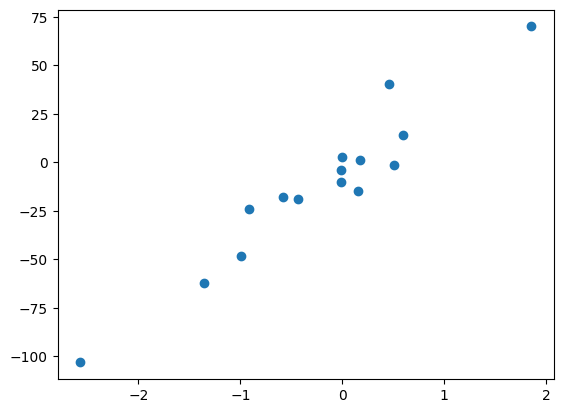

In [153]:
plt.Figure(figsize=(12,8))
plt.scatter(x_train, y_train)
plt.show()

In [154]:
# initialize the training dataset & enable grad
X_train = torch.from_numpy(x_train).float()
Y_train = torch.from_numpy(y_train).float().reshape(-1, 1)

X_train.requires_grad_()
Y_train.requires_grad_()
print('requires grad for X:', X_train.requires_grad)
print('requires grad for Y:', Y_train.requires_grad)

requires grad for X: True
requires grad for Y: True


In [155]:
# set the neural network architecture
input_size = 1
hidden_size = 1
output_size = 1
learning_rate = 1e-3


In [156]:
# initialize the weights
w1 = torch.rand(input_size, hidden_size, requires_grad=True)
w2 = torch.rand(hidden_size, output_size, requires_grad=True)
b = torch.rand(1, requires_grad=True) # Added Bias
w1.shape, w2.shape

(torch.Size([1, 1]), torch.Size([1, 1]))

In [157]:
# Training Loop
for i in range(1, 10000):
    # Forward pass: y = x * w1 * w2 + b
    y_pred = X_train.mm(w1).mm(w2) + b 
    
    # Loss function (MSE)
    loss = (y_pred - Y_train).pow(2).mean()

    if i % 1000 == 0:
        print(f"Iteration {i}: Loss {loss.item():.4f}")

    # Backward pass
    loss.backward()

    # Update weights (Manual Gradient Descent)
    with torch.no_grad():
        w1 -= learning_rate * w1.grad
        w2 -= learning_rate * w2.grad
        b  -= learning_rate * b.grad

        # Zero gradients
        w1.grad.zero_()
        w2.grad.zero_()
        b.grad.zero_()

print("\nFinal Weights and Bias:")
print(f"w1: {w1.item():.4f}")
print(f"w2: {w2.item():.4f}")
print(f"b:  {b.item():.4f}")

Iteration 1000: Loss 119.6889
Iteration 2000: Loss 119.3526
Iteration 3000: Loss 119.3452
Iteration 4000: Loss 119.3451
Iteration 5000: Loss 119.3451
Iteration 6000: Loss 119.3451
Iteration 7000: Loss 119.3451
Iteration 8000: Loss 119.3451
Iteration 9000: Loss 119.3451

Final Weights and Bias:
w1: 6.2193
w2: 6.1859
b:  -3.6986


In [158]:
# model output
print('w1', w1)
print('w2', w2)

w1 tensor([[6.2193]], requires_grad=True)
w2 tensor([[6.1859]], requires_grad=True)


In [159]:
predicted = y_pred.detach().numpy()
predicted

array([[ -39.082794 ],
       [  15.864187 ],
       [  19.170326 ],
       [ -26.255129 ],
       [-102.544334 ],
       [  -3.8787296],
       [ -20.386871 ],
       [   2.2011206],
       [ -41.97444  ],
       [  -4.1905303],
       [  13.845785 ],
       [  -4.145648 ],
       [   2.819339 ],
       [ -55.79865  ],
       [  67.53213  ]], dtype=float32)

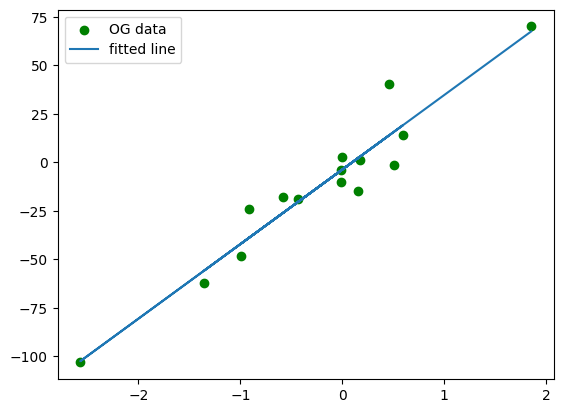

In [160]:
plt.Figure(figsize=(12,8))
plt.scatter(x_train, y_train, label='OG data', c='g')
plt.plot(x_train, predicted, label='fitted line')
plt.legend()
plt.show()

In [161]:
print(f"X_train shape: {X_train.shape}")
print(f"Y_train shape: {Y_train.shape}")
print(f"w1 shape: {w1.shape}")
print(f"w2 shape: {w2.shape}")

X_train shape: torch.Size([15, 1])
Y_train shape: torch.Size([15, 1])
w1 shape: torch.Size([1, 1])
w2 shape: torch.Size([1, 1])


# Dynamic Computation Graphs
- neural network is a computation graph of computations and tensors
    - directed acyclic graph
    - nodes/edges = computations/data
- PyTorch graphs are dynamic
    - imperative programming
        - graph is defined as it is executed
        - no separate phases to build and execute
        - computation directly performed on real operands
        - 'define by run'
        - more flexible, can show intermediary results
- TensorFlow
    - static -> symbolic programming
        - define then execute
        - define in abstract manner, no actual computation takes place
        - computation explictly compiled before evaluation
        - easier to optimize and parallelize
- pip install:
    - graphviz
    - torchviz
    - hiddenlayer: used to view hidden layers of neural networks

In [178]:
import numpy as np
import torch
import torch.nn as nn

w = torch.randn(6)
x = torch.full((6,), 10, dtype=torch.float16)
b = torch.tensor(3, dtype=torch.float16)



In [179]:
w, x, b

(tensor([-0.7343, -0.1404,  0.3655,  0.1596, -0.2888,  0.4894]),
 tensor([10., 10., 10., 10., 10., 10.], dtype=torch.float16),
 tensor(3., dtype=torch.float16))

In [180]:
class SimpleModel(nn.Module):
    def __init__(self, w, b):
        super().__init__()
        self.w = nn.Parameter(w)
        self.b = nn.Parameter(b)
    
    def forward(self, x):
        return self.w * x + self.b

model = SimpleModel(w, b)